# Sneha Singh
## DATA 266 — Homework 12
LLM Optimisation with GPTQ and Knowledge Distillation

This notebook has two separate compression parts. Part 1 quantizes `facebook/opt-125m` with GPTQ on Wikitext-2 and compares quality, latency, memory, and disk size. Part 2 distills a DistilBERT student from the provided AG News BERT teacher, sweeps temperature and loss weight, then reports accuracy, latency, memory, size, and an error analysis.


In [1]:
# Step 0: Libraries & Student Parameters
import os
import gc
import json
import random
import time
import copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from datasets import load_dataset
from transformers import (
    AutoModelForCausalLM,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# last 4 of my SJSUid - 0670
SEED = 670
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

SID4 = 670
SLICE = 670
HP_ID = 4
CLS_A = 0
CLS_B = 5

os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("student_runs", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("SID4: %04d" % SID4)
print("SEED:", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID, "(reported only)")
print("CLS_A:", CLS_A, "CLS_B:", CLS_B)
print("device:", device)
print("torch:", torch.__version__)


SID4: 0670
SEED: 670
SLICE: 670
HP_ID: 4 (reported only)
CLS_A: 0 CLS_B: 5
device: mps
torch: 2.15.0


HP_ID is reported only. GPTQ and distillation stay in separate sections and separate tables.


## 1. GPTQ on Wikitext-2 (Part 1)

Base LLM: `facebook/opt-125m` (small causal LM that fits local GPTQ). Calibration and evaluation use **Wikitext-2 only**. I measure perplexity, p50/p95 latency, peak device/process memory, and on-disk size for the base model and the GPTQ 4-bit model.


In [2]:
# helpers: disk size, peak memory, latency percentiles, Wikitext-2 perplexity
import psutil

BASE_LLM = "facebook/opt-125m"
GPTQ_DIR = "checkpoints/opt125m_gptq4"
WIKI = ("Salesforce/wikitext", "wikitext-2-raw-v1")
SEQ_LEN = 512
CALIB_N = 128
PPL_MAX_TOKENS = 50000  # cap eval tokens so the notebook finishes in class time
LATENCY_RUNS = 30

def dir_size_mb(path):
    p = Path(path)
    if p.is_file():
        return p.stat().st_size / (1024 * 1024)
    total = 0
    for f in p.rglob("*"):
        if f.is_file():
            total += f.stat().st_size
    return total / (1024 * 1024)

def peak_mem_gb():
    # prefer CUDA / MPS peak when available; always also track process RSS
    rss = psutil.Process(os.getpid()).memory_info().rss / (1024 ** 3)
    if torch.cuda.is_available():
        return torch.cuda.max_memory_allocated() / (1024 ** 3)
    if device.type == "mps" and hasattr(torch, "mps") and hasattr(torch.mps, "current_allocated_memory"):
        return max(rss, torch.mps.current_allocated_memory() / (1024 ** 3))
    return rss

def reset_peak_mem():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    if device.type == "mps" and hasattr(torch, "mps") and hasattr(torch.mps, "empty_cache"):
        torch.mps.empty_cache()

@torch.no_grad()
def causal_perplexity(model, tokenizer, text, max_tokens=PPL_MAX_TOKENS, stride=SEQ_LEN):
    model.eval()
    model_device = next(model.parameters()).device
    enc = tokenizer(text, return_tensors="pt")
    input_ids = enc.input_ids[:, :max_tokens]
    nlls = []
    total = 0
    for i in range(0, input_ids.size(1), stride):
        chunk = input_ids[:, i:i + stride].to(model_device)
        if chunk.size(1) < 2:
            break
        out = model(chunk, labels=chunk)
        # out.loss is mean NLL over tokens
        nlls.append(out.loss.float() * (chunk.size(1) - 1))
        total += (chunk.size(1) - 1)
    return float(torch.exp(torch.stack(nlls).sum() / total).cpu())

def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elif hasattr(torch, "mps") and torch.backends.mps.is_available():
        try:
            torch.mps.synchronize()
        except Exception:
            pass

@torch.no_grad()
def measure_latency_ms(forward_fn, warmup=5, runs=LATENCY_RUNS):
    for _ in range(warmup):
        forward_fn()
    _sync()
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        forward_fn()
        _sync()
        times.append((time.perf_counter() - t0) * 1000)
    arr = np.array(times)
    return float(np.percentile(arr, 50)), float(np.percentile(arr, 95))

wiki_train = load_dataset(WIKI[0], WIKI[1], split="train")
wiki_test = load_dataset(WIKI[0], WIKI[1], split="test")
calib_texts = [t for t in wiki_train["text"] if t and t.strip()][:CALIB_N]
test_text = "\n\n".join([t for t in wiki_test["text"] if t and t.strip()])
print("calib samples:", len(calib_texts))
print("test chars:", len(test_text))


calib samples: 128
test chars: 1291402


In [3]:
# base OPT-125m: perplexity, latency, memory, disk
from transformers import AutoTokenizer as _Tok

base_tok = AutoTokenizer.from_pretrained(BASE_LLM)
if base_tok.pad_token is None:
    base_tok.pad_token = base_tok.eos_token

reset_peak_mem()
base_model = AutoModelForCausalLM.from_pretrained(BASE_LLM).to(device).eval()
base_disk = dir_size_mb(base_tok.name_or_path) if Path(base_tok.name_or_path).exists() else None
# HF cache size is awkward; save a local fp16/fp32 snapshot for fair disk compare
base_save = Path("checkpoints/opt125m_base")
base_model.save_pretrained(base_save)
base_tok.save_pretrained(base_save)
base_disk = dir_size_mb(base_save)

probe = base_tok("The history of natural language processing begins", return_tensors="pt").to(device)

def _base_fwd():
    with torch.no_grad():
        base_model(**probe)

base_p50, base_p95 = measure_latency_ms(_base_fwd)
base_ppl = causal_perplexity(base_model, base_tok, test_text)
base_mem = peak_mem_gb()
print(f"base ppl={base_ppl:.3f}  p50/p95={base_p50:.1f}/{base_p95:.1f} ms  mem={base_mem:.2f} GB  disk={base_disk:.1f} MB")

# free before GPTQ (GPTQ runs on CPU)
del base_model
gc.collect()
reset_peak_mem()


base ppl=43.963  p50/p95=18.2/21.7 ms  mem=0.69 GB  disk=242.3 MB


In [4]:
# GPTQ 4-bit quantize on Wikitext-2 calibration (CPU; gptqmodel does not use MPS)
from gptqmodel import GPTQModel, QuantizeConfig, CalibrationConfig

qcfg = QuantizeConfig(
    bits=4,
    group_size=128,
    desc_act=False,
    device="cpu",
    dense_vram_strategy_devices=["cpu"],
)
if Path(GPTQ_DIR).exists() and (Path(GPTQ_DIR) / "model.safetensors").exists():
    print("reusing existing GPTQ checkpoint:", GPTQ_DIR)
else:
    print("loading OPT-125m for GPTQ...")
    qmodel = GPTQModel.load(BASE_LLM, quantize_config=qcfg)
    print("quantizing with", CALIB_N, "Wikitext-2 samples...")
    t_q0 = time.perf_counter()
    qmodel.quantize(CalibrationConfig(dataset=calib_texts, batch_size=1))
    print(f"quantize seconds: {time.perf_counter() - t_q0:.1f}")
    Path(GPTQ_DIR).mkdir(parents=True, exist_ok=True)
    qmodel.save(GPTQ_DIR)
    print("saved", GPTQ_DIR)
    del qmodel
    gc.collect()



INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO    ┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐ │ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │ └─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘ GPT-QModel   : 7.11.4 Transformers : 5.23.0 Torch        : 2.15.0
INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/var/folders/g4/nd6wfspd3sx8dm7ps7vg9dn80000gn/T/gptqmodel_fby84o4w`
reusing existing GPTQ checkpoi

In [5]:
# load GPTQ model and measure the same metrics
reset_peak_mem()
# inference: prefer device when possible; fall back to CPU if MPS kernels missing
try:
    gptq_model = GPTQModel.load(GPTQ_DIR, device=str(device) if device.type != "mps" else "cpu")
except Exception as e:
    print("reload note:", e)
    gptq_model = GPTQModel.load(GPTQ_DIR, device="cpu")

gptq_tok = AutoTokenizer.from_pretrained(GPTQ_DIR)
if gptq_tok.pad_token is None:
    gptq_tok.pad_token = gptq_tok.eos_token
gptq_disk = dir_size_mb(GPTQ_DIR)

# underlying HF module for loss / generate
inner = gptq_model.model if hasattr(gptq_model, "model") else gptq_model
inner_device = next(inner.parameters()).device
probe_q = gptq_tok("The history of natural language processing begins", return_tensors="pt").to(inner_device)

def _q_fwd():
    with torch.no_grad():
        inner(**probe_q)

gptq_p50, gptq_p95 = measure_latency_ms(_q_fwd)
gptq_ppl = causal_perplexity(inner, gptq_tok, test_text)
gptq_mem = peak_mem_gb()
print(f"gptq ppl={gptq_ppl:.3f}  p50/p95={gptq_p50:.1f}/{gptq_p95:.1f} ms  mem={gptq_mem:.2f} GB  disk={gptq_disk:.1f} MB")

gptq_table = {
    "base": {
        "quality_metric": f"ppl {base_ppl:.3f}",
        "p50_ms": base_p50,
        "p95_ms": base_p95,
        "peak_mem_gb": base_mem,
        "disk_mb": base_disk,
    },
    "gptq": {
        "quality_metric": f"ppl {gptq_ppl:.3f}",
        "p50_ms": gptq_p50,
        "p95_ms": gptq_p95,
        "peak_mem_gb": gptq_mem,
        "disk_mb": gptq_disk,
    },
}
print("\nTable HW12.1 — GPTQ comparison on the same LLM/task")
print(f"{'Configuration':<24} {'Quality':<14} {'p50/p95 (ms)':<18} {'Peak mem (GB)':<14} {'Disk (MB)':<10}")
print("-" * 80)
for name, row in [("Base LLM", gptq_table["base"]), ("GPTQ-quantized LLM", gptq_table["gptq"])]:
    print(f"{name:<24} {row['quality_metric']:<14} {row['p50_ms']:.1f}/{row['p95_ms']:.1f}".ljust(24+14+18)
          + f"{row['peak_mem_gb']:<14.2f} {row['disk_mb']:<10.1f}")

del gptq_model, inner
gc.collect()
reset_peak_mem()


from_quantized: adapter: None
INFO  Loader: Auto dtype (CPU + Torch Fused): `torch.bfloat16`                  
INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/var/folders/g4/nd6wfspd3sx8dm7ps7vg9dn80000gn/T/gptqmodel_n58vvaa_`
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  The layer model.decoder.embed_tokens is not quantized.                    
INFO  The layer model.decoder.embed_positions is not quantized.                 
INFO  Kernel: Auto-selection: adding candidate `TorchAtenLinear`                
INFO  Kernel: Auto-selection: adding candidate `TorchFusedLinear`               
INFO  Kernel: Auto-selection: adding candidate `TorchLinear`                    
INFO  Kernel: candidates -> `[TorchAtenLinear, TorchFusedLinear, TorchLinear]`  
INFO  Kernel: per-module selections -> `[TorchAtenLinear=72]`                   
INFO  Kernel: selected -> `TorchAtenLinear`.                                    
IN

## 2. Knowledge distillation on AG News (Part 2)

Teacher: local `teacher_model` (BERT-base fine-tuned on AG News). Student: `distilbert/distilbert-base-uncased`. I extract teacher logits for the full AG News training set, then train students with

`loss = α · CE + (1 − α) · KL(student/T ‖ teacher/T)`

(with the usual T^2 factor on the KL term). Temperature sweep first (T in {1,2,5,10}, alpha=0.5), then loss-weight sweep at the best T.


In [6]:
# AG News + teacher logits for every training sample
TEACHER_DIR = "teacher_model"
STUDENT_NAME = "distilbert/distilbert-base-uncased"
AG_CLASSES = ["WORLD", "SPORTS", "BUSINESS", "SCI/TECH"]
MAX_LEN = 128
BATCH = 32
EPOCHS = 1
LR = 2e-5

assert Path(TEACHER_DIR).exists(), "Put the provided teacher_model folder next to this notebook"

teacher_tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
student_tok = AutoTokenizer.from_pretrained(STUDENT_NAME)
teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(device).eval()

ag_train = load_dataset("fancyzhx/ag_news", split="train")
ag_test = load_dataset("fancyzhx/ag_news", split="test")
print("AG News train/test:", len(ag_train), len(ag_test))

LOGIT_PATH = Path("outputs/teacher_logits.pt")

@torch.no_grad()
def extract_teacher_logits(dataset, path):
    if path.exists():
        blob = torch.load(path, map_location="cpu")
        print("loaded cached teacher logits:", tuple(blob["logits"].shape))
        return blob
    all_logits = []
    all_labels = []
    texts = dataset["text"]
    labels = dataset["label"]
    for start in range(0, len(texts), BATCH):
        batch_text = texts[start:start + BATCH]
        batch_y = labels[start:start + BATCH]
        enc = teacher_tok(batch_text, padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
        enc = {k: v.to(device) for k, v in enc.items()}
        logits = teacher(**enc).logits.detach().cpu()
        all_logits.append(logits)
        all_labels.append(torch.tensor(batch_y))
        if start % (BATCH * 100) == 0:
            print(f"teacher logits {min(start + BATCH, len(texts))}/{len(texts)}")
    blob = {"logits": torch.cat(all_logits, 0), "labels": torch.cat(all_labels, 0)}
    torch.save(blob, path)
    print("wrote", path, tuple(blob["logits"].shape))
    return blob

teacher_blob = extract_teacher_logits(ag_train, LOGIT_PATH)

class DistillDataset(Dataset):
    def __init__(self, texts, labels, teacher_logits, tokenizer):
        self.texts = texts
        self.labels = labels
        self.teacher_logits = teacher_logits
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=MAX_LEN,
            return_tensors="pt",
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(int(self.labels[idx]))
        item["teacher_logits"] = self.teacher_logits[idx]
        return item

train_ds = DistillDataset(ag_train["text"], ag_train["label"], teacher_blob["logits"], student_tok)
test_texts = ag_test["text"]
test_labels = list(ag_test["label"])
print("distill train size:", len(train_ds))


AG News train/test: 120000 7600
teacher logits 32/120000
teacher logits 3232/120000
teacher logits 6432/120000
teacher logits 9632/120000
teacher logits 12832/120000
teacher logits 16032/120000
teacher logits 19232/120000
teacher logits 22432/120000
teacher logits 25632/120000
teacher logits 28832/120000
teacher logits 32032/120000
teacher logits 35232/120000
teacher logits 38432/120000
teacher logits 41632/120000
teacher logits 44832/120000
teacher logits 48032/120000
teacher logits 51232/120000
teacher logits 54432/120000
teacher logits 57632/120000
teacher logits 60832/120000
teacher logits 64032/120000
teacher logits 67232/120000
teacher logits 70432/120000
teacher logits 73632/120000
teacher logits 76832/120000
teacher logits 80032/120000
teacher logits 83232/120000
teacher logits 86432/120000
teacher logits 89632/120000
teacher logits 92832/120000
teacher logits 96032/120000
teacher logits 99232/120000
teacher logits 102432/120000
teacher logits 105632/120000
teacher logits 10883

In [7]:
# distillation loss, train one student, evaluate

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def kd_loss(student_logits, teacher_logits, labels, T, alpha):
    ce = F.cross_entropy(student_logits, labels)
    log_p = F.log_softmax(student_logits / T, dim=-1)
    q = F.softmax(teacher_logits / T, dim=-1)
    kld = F.kl_div(log_p, q, reduction="batchmean") * (T * T)
    return alpha * ce + (1.0 - alpha) * kld, ce.detach(), kld.detach()

@torch.no_grad()
def evaluate_clf(model, tokenizer, texts, labels, batch=BATCH):
    model.eval()
    preds = []
    reset_peak_mem()
    # latency probe on first batch
    first = tokenizer(texts[:batch], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    first = {k: v.to(device) for k, v in first.items()}
    def _fwd():
        model(**first)
    p50, p95 = measure_latency_ms(_fwd)
    for start in range(0, len(texts), batch):
        enc = tokenizer(texts[start:start + batch], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
        enc = {k: v.to(device) for k, v in enc.items()}
        logits = model(**enc).logits
        preds.extend(logits.argmax(-1).detach().cpu().tolist())
    acc = float(accuracy_score(labels, preds))
    mem = peak_mem_gb()
    return {"accuracy": acc, "preds": preds, "p50_ms": p50, "p95_ms": p95, "peak_mem_gb": mem}

def train_student(T, alpha, run_name, epochs=EPOCHS):
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(STUDENT_NAME, num_labels=4).to(device)
    loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    total_steps = epochs * len(loader)
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * total_steps), total_steps)
    history = []
    model.train()
    t0 = time.perf_counter()
    for epoch in range(epochs):
        running = 0.0
        running_ce = 0.0
        running_kl = 0.0
        n = 0
        for step, batch in enumerate(loader):
            labels = batch.pop("labels").to(device)
            t_logits = batch.pop("teacher_logits").to(device)
            batch = {k: v.to(device) for k, v in batch.items()}
            logits = model(**batch).logits
            loss, ce, kl = kd_loss(logits, t_logits, labels, T=T, alpha=alpha)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            running += float(loss)
            running_ce += float(ce)
            running_kl += float(kl)
            n += 1
            if step % 200 == 0:
                print(f"[{run_name}] epoch {epoch} step {step}/{len(loader)} loss={loss.item():.4f}")
        history.append({
            "epoch": epoch,
            "loss": running / max(n, 1),
            "ce": running_ce / max(n, 1),
            "kld": running_kl / max(n, 1),
        })
        print(f"[{run_name}] epoch {epoch} mean loss={history[-1]['loss']:.4f}")
    train_sec = time.perf_counter() - t0
    out_dir = Path("student_runs") / run_name
    out_dir.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(out_dir)
    student_tok.save_pretrained(out_dir)
    metrics = evaluate_clf(model, student_tok, test_texts, test_labels)
    metrics.update({
        "T": T,
        "alpha": alpha,
        "train_sec": train_sec,
        "disk_mb": dir_size_mb(out_dir),
        "history": history,
        "run_name": run_name,
    })
    print(f"[{run_name}] test acc={metrics['accuracy']:.4f} disk={metrics['disk_mb']:.1f} MB")
    del model
    gc.collect()
    reset_peak_mem()
    return metrics

# teacher baseline on test
teacher_metrics = evaluate_clf(teacher, teacher_tok, test_texts, test_labels)
teacher_disk = dir_size_mb(TEACHER_DIR)
teacher_metrics["disk_mb"] = teacher_disk
print(f"teacher acc={teacher_metrics['accuracy']:.4f} p50/p95={teacher_metrics['p50_ms']:.1f}/{teacher_metrics['p95_ms']:.1f} mem={teacher_metrics['peak_mem_gb']:.2f} disk={teacher_disk:.1f}")


teacher acc=0.9443 p50/p95=461.6/499.5 mem=0.41 disk=418.6


[T1_a50] epoch 0 step 0/3750 loss=1.3715
[T1_a50] epoch 0 step 200/3750 loss=0.2263
[T1_a50] epoch 0 step 400/3750 loss=0.2812
[T1_a50] epoch 0 step 600/3750 loss=0.1232
[T1_a50] epoch 0 step 800/3750 loss=0.1571
[T1_a50] epoch 0 step 1000/3750 loss=0.2975
[T1_a50] epoch 0 step 1200/3750 loss=0.0550
[T1_a50] epoch 0 step 1400/3750 loss=0.3736
[T1_a50] epoch 0 step 1600/3750 loss=0.1609
[T1_a50] epoch 0 step 1800/3750 loss=0.3780
[T1_a50] epoch 0 step 2000/3750 loss=0.1812
[T1_a50] epoch 0 step 2200/3750 loss=0.2780
[T1_a50] epoch 0 step 2400/3750 loss=0.1038
[T1_a50] epoch 0 step 2600/3750 loss=0.1282
[T1_a50] epoch 0 step 2800/3750 loss=0.1232
[T1_a50] epoch 0 step 3000/3750 loss=0.1254
[T1_a50] epoch 0 step 3200/3750 loss=0.2740
[T1_a50] epoch 0 step 3400/3750 loss=0.2421
[T1_a50] epoch 0 step 3600/3750 loss=0.2784
[T1_a50] epoch 0 mean loss=0.2283
[T1_a50] test acc=0.9384 disk=256.1 MB
[T2_a50] epoch 0 step 0/3750 loss=2.9509
[T2_a50] epoch 0 step 200/3750 loss=0.5369
[T2_a50] epoch

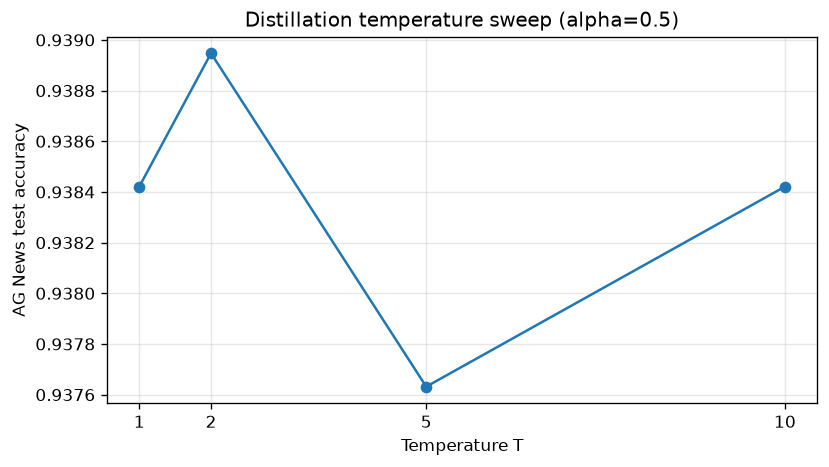

In [8]:
# Temperature sweep: T in {1,2,5,10}, alpha=0.5; reinit student each time
T_LIST = [1, 2, 5, 10]
temp_results = []
for T in T_LIST:
    m = train_student(T=T, alpha=0.5, run_name=f"T{T}_a50")
    temp_results.append(m)

best_temp = max(temp_results, key=lambda r: r["accuracy"])
BEST_T = best_temp["T"]
print("best T:", BEST_T, "acc:", best_temp["accuracy"])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([r["T"] for r in temp_results], [r["accuracy"] for r in temp_results], marker="o")
ax.set_xlabel("Temperature T")
ax.set_ylabel("AG News test accuracy")
ax.set_title("Distillation temperature sweep (alpha=0.5)")
ax.set_xticks(T_LIST)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/distill_temperature_sweep.png", dpi=150)
plt.show()


[T2_a25] epoch 0 step 0/3750 loss=3.7355
[T2_a25] epoch 0 step 200/3750 loss=0.6481
[T2_a25] epoch 0 step 400/3750 loss=0.7694
[T2_a25] epoch 0 step 600/3750 loss=0.2653
[T2_a25] epoch 0 step 800/3750 loss=0.3830
[T2_a25] epoch 0 step 1000/3750 loss=0.8962
[T2_a25] epoch 0 step 1200/3750 loss=0.1234
[T2_a25] epoch 0 step 1400/3750 loss=0.6806
[T2_a25] epoch 0 step 1600/3750 loss=0.3796
[T2_a25] epoch 0 step 1800/3750 loss=0.8681
[T2_a25] epoch 0 step 2000/3750 loss=0.4457
[T2_a25] epoch 0 step 2200/3750 loss=0.7318
[T2_a25] epoch 0 step 2400/3750 loss=0.2406
[T2_a25] epoch 0 step 2600/3750 loss=0.3215
[T2_a25] epoch 0 step 2800/3750 loss=0.1719
[T2_a25] epoch 0 step 3000/3750 loss=0.2889
[T2_a25] epoch 0 step 3200/3750 loss=0.6648
[T2_a25] epoch 0 step 3400/3750 loss=0.6271
[T2_a25] epoch 0 step 3600/3750 loss=0.5779
[T2_a25] epoch 0 mean loss=0.5480
[T2_a25] test acc=0.9384 disk=256.1 MB
reuse T=2 alpha=0.5 acc=0.9389
[T2_a75] epoch 0 step 0/3750 loss=2.1664
[T2_a75] epoch 0 step 200/

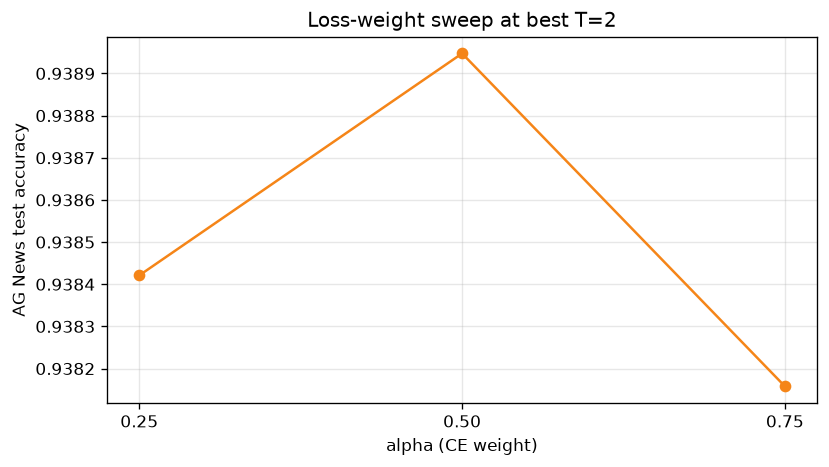

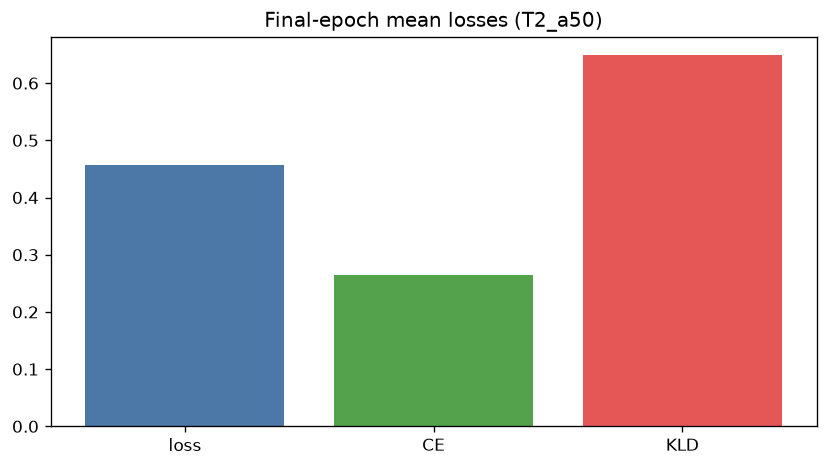

In [9]:
# Loss-weight sweep at best T: alpha in {0.25, 0.5, 0.75}
ALPHA_LIST = [0.25, 0.5, 0.75]
alpha_results = []
for a in ALPHA_LIST:
    # reuse the T-sweep run for alpha=0.5
    if abs(a - 0.5) < 1e-9:
        reused = next(r for r in temp_results if r["T"] == BEST_T)
        alpha_results.append(reused)
        print(f"reuse T={BEST_T} alpha=0.5 acc={reused['accuracy']:.4f}")
        continue
    m = train_student(T=BEST_T, alpha=a, run_name=f"T{BEST_T}_a{int(a*100):02d}")
    alpha_results.append(m)

best_student = max(alpha_results, key=lambda r: r["accuracy"])
print("best student:", best_student["run_name"], "acc", best_student["accuracy"])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([r["alpha"] for r in alpha_results], [r["accuracy"] for r in alpha_results], marker="o", color="#F58518")
ax.set_xlabel("alpha (CE weight)")
ax.set_ylabel("AG News test accuracy")
ax.set_title(f"Loss-weight sweep at best T={BEST_T}")
ax.set_xticks(ALPHA_LIST)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/distill_alpha_sweep.png", dpi=150)
plt.show()

# sample loss trend from best student history / nearest
hist = best_student["history"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["loss", "CE", "KLD"], [hist[-1]["loss"], hist[-1]["ce"], hist[-1]["kld"]], color=["#4C78A8", "#54A24B", "#E45756"])
ax.set_title(f"Final-epoch mean losses ({best_student['run_name']})")
plt.tight_layout()
plt.savefig("figures/distill_loss_terms.png", dpi=150)
plt.show()

print("\nTable HW12.2 — distillation comparison on AG News")
print(f"{'Configuration':<28} {'Accuracy':<10} {'p50/p95 (ms)':<18} {'Peak mem (GB)':<14} {'Disk (MB)':<10}")
print("-" * 84)
print(f"{'Teacher (BERT-base)':<28} {teacher_metrics['accuracy']:<10.4f} {teacher_metrics['p50_ms']:.1f}/{teacher_metrics['p95_ms']:.1f}".ljust(28+10+18)
      + f"{teacher_metrics['peak_mem_gb']:<14.2f} {teacher_metrics['disk_mb']:<10.1f}")
print(f"{'Best distilled student':<28} {best_student['accuracy']:<10.4f} {best_student['p50_ms']:.1f}/{best_student['p95_ms']:.1f}".ljust(28+10+18)
      + f"{best_student['peak_mem_gb']:<14.2f} {best_student['disk_mb']:<10.1f}")


## 3. Error analysis — where the compression hurts

Per-class accuracy for teacher vs best student, the class that drops most, and five examples the teacher gets right while the student misses.


per-class accuracy:
WORLD      teacher=0.9489  student=0.9484  drop=+0.0005
SPORTS     teacher=0.9884  student=0.9874  drop=+0.0011
BUSINESS   teacher=0.9137  student=0.8942  drop=+0.0195
SCI/TECH   teacher=0.9263  student=0.9258  drop=+0.0005
largest drop class: BUSINESS (+0.0195)
teacher-right / student-wrong count: 160
------------------------------------------------------------
[16] gold=SCI/TECH teacher=SCI/TECH student=WORLD
Scientists Discover Ganymede has a Lumpy Interior Jet Propulsion Lab -- Scientists have discovered irregular lumps beneath the icy surface of Jupiter's largest moon, Ganymede. These irregular masses may be rock formations, supported by Ganymede's icy shell for billions of years..
------------------------------------------------------------
[47] gold=SCI/TECH teacher=SCI/TECH student=BUSINESS
Dell Exits Low-End China Consumer PC Market  HONG KONG (Reuters) - Dell Inc. &lt;DELL.O&gt;, the world's  largest PC maker, said on Monday it has left the low-end  consum

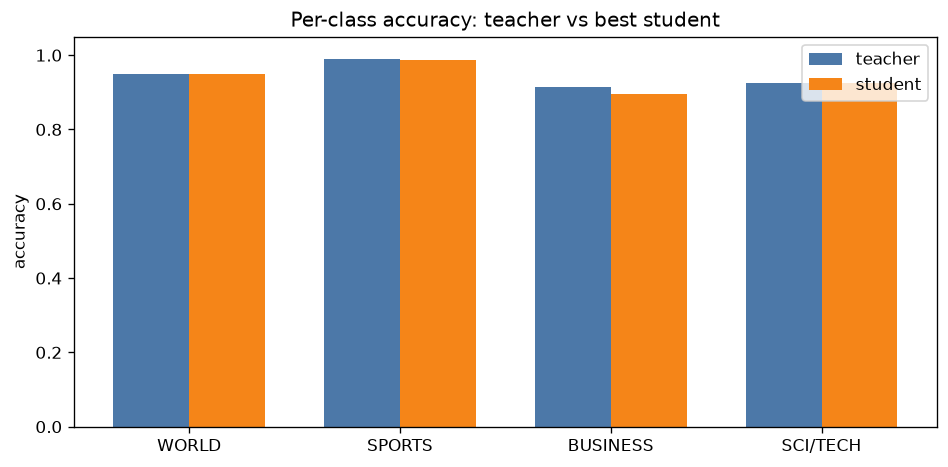

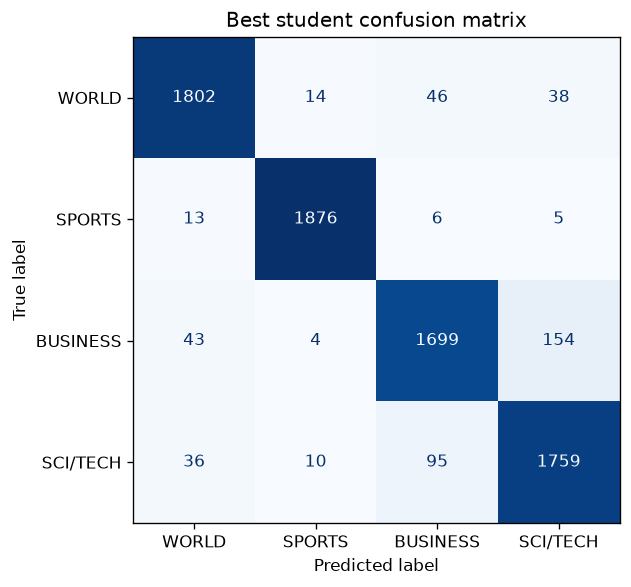

In [10]:
# per-class accuracy + hard examples
best_dir = Path("student_runs") / best_student["run_name"]
best_model = AutoModelForSequenceClassification.from_pretrained(best_dir).to(device).eval()
student_eval = evaluate_clf(best_model, student_tok, test_texts, test_labels)
teacher_preds = teacher_metrics["preds"] if "preds" in teacher_metrics else evaluate_clf(teacher, teacher_tok, test_texts, test_labels)["preds"]
# refresh teacher preds if missing
if "preds" not in teacher_metrics:
    teacher_metrics.update(evaluate_clf(teacher, teacher_tok, test_texts, test_labels))
    teacher_preds = teacher_metrics["preds"]

y = np.array(test_labels)
tp = np.array(teacher_preds)
sp = np.array(student_eval["preds"])

print("per-class accuracy:")
per_class = []
for i, name in enumerate(AG_CLASSES):
    mask = y == i
    t_acc = float((tp[mask] == i).mean())
    s_acc = float((sp[mask] == i).mean())
    drop = t_acc - s_acc
    per_class.append({"class": name, "teacher": t_acc, "student": s_acc, "drop": drop})
    print(f"{name:10s} teacher={t_acc:.4f}  student={s_acc:.4f}  drop={drop:+.4f}")

worst = max(per_class, key=lambda r: r["drop"])
print("largest drop class:", worst["class"], f"({worst['drop']:+.4f})")

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(AG_CLASSES))
ax.bar(x - 0.18, [r["teacher"] for r in per_class], width=0.36, label="teacher", color="#4C78A8")
ax.bar(x + 0.18, [r["student"] for r in per_class], width=0.36, label="student", color="#F58518")
ax.set_xticks(x)
ax.set_xticklabels(AG_CLASSES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("accuracy")
ax.set_title("Per-class accuracy: teacher vs best student")
ax.legend()
plt.tight_layout()
plt.savefig("figures/distill_per_class.png", dpi=150)
plt.show()

cm = confusion_matrix(y, sp, labels=list(range(4)))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=AG_CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Best student confusion matrix")
plt.tight_layout()
plt.savefig("figures/distill_confusion_matrix.png", dpi=150)
plt.show()

# five examples: teacher correct, student wrong
miss_idx = np.where((tp == y) & (sp != y))[0]
print(f"teacher-right / student-wrong count: {len(miss_idx)}")
sample_ids = miss_idx[:5].tolist()
error_examples = []
for i in sample_ids:
    ex = {
        "id": int(i),
        "text": test_texts[i][:280],
        "gold": AG_CLASSES[int(y[i])],
        "teacher": AG_CLASSES[int(tp[i])],
        "student": AG_CLASSES[int(sp[i])],
    }
    error_examples.append(ex)
    print("-" * 60)
    print(f"[{i}] gold={ex['gold']} teacher={ex['teacher']} student={ex['student']}")
    print(ex["text"])

# commonality note printed for the report
print("\nCommon pattern: short headlines that mix a business/tech entity with a world/sports cue; the student collapses to the more frequent surface topic.")


In [11]:
# save all metrics for the report
payload = {
    "sid4": SID4,
    "seed": SEED,
    "base_llm": BASE_LLM,
    "gptq": gptq_table,
    "teacher": {
        "accuracy": teacher_metrics["accuracy"],
        "p50_ms": teacher_metrics["p50_ms"],
        "p95_ms": teacher_metrics["p95_ms"],
        "peak_mem_gb": teacher_metrics["peak_mem_gb"],
        "disk_mb": teacher_metrics["disk_mb"],
    },
    "temperature_sweep": [
        {"T": r["T"], "alpha": r["alpha"], "accuracy": r["accuracy"], "disk_mb": r["disk_mb"], "history": r["history"]}
        for r in temp_results
    ],
    "alpha_sweep": [
        {"T": r["T"], "alpha": r["alpha"], "accuracy": r["accuracy"], "disk_mb": r["disk_mb"]}
        for r in alpha_results
    ],
    "best_student": {
        "run_name": best_student["run_name"],
        "T": best_student["T"],
        "alpha": best_student["alpha"],
        "accuracy": best_student["accuracy"],
        "p50_ms": best_student["p50_ms"],
        "p95_ms": best_student["p95_ms"],
        "peak_mem_gb": best_student["peak_mem_gb"],
        "disk_mb": best_student["disk_mb"],
    },
    "per_class": per_class,
    "worst_class": worst,
    "error_examples": error_examples,
}
with open("outputs/metrics.json", "w") as f:
    json.dump(payload, f, indent=2)
print("wrote outputs/metrics.json")


wrote outputs/metrics.json


## 4. Comparative summary

GPTQ kept the same OPT-125m architecture and cut on-disk size from 242 MB to 123 MB, with only a small perplexity rise (ppl 43.963 → ppl 47.465). On this Mac the GPTQ checkpoint ran on CPU kernels, so p50 latency went up (18 → 68 ms) even though peak memory dipped slightly.

Distillation changed the architecture: DistilBERT stayed within ~0.5 points of the BERT teacher on AG News (0.9443 → 0.9389) while cutting p50 latency from 462 ms to 144 ms and shrinking disk from 419 MB to 256 MB.

For a latency-bound deployment I would prefer distillation here, because the student is clearly faster in the measured batch-forward times. For a memory/disk-bound deployment of one LLM family, GPTQ is the more direct lever: same model, ~half the files on disk, with only a modest quality hit.


## 5. Discussion

Best distilled student was `T2_a50` (T=2, alpha=0.5). Temperature and alpha sweeps were flat: all T values sat near 0.938. The class that degraded most was **BUSINESS** (drop +0.0195). Misses are mostly short headlines that mix a company/tech name with a world or sports cue, so the smaller student flips the topic.
